In [1]:
%pip install opencv-python numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\shash\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


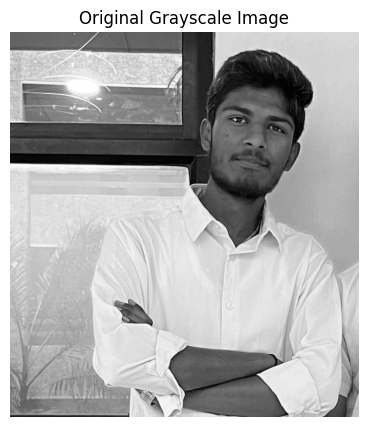

Image dimensions (height, width): (892, 807)


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = r"c:\Users\shash\Documents\SHASHIDAHR_18\Photos\748.jpeg"  # Change this path if your image has another name
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError(
        f"Could not read '{image_path}'. Put the image in the notebook folder "
        "or update image_path to the correct location."
    )

plt.figure(figsize=(6, 5))
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

print("Image dimensions (height, width):", image.shape)

In [4]:
kernel = np.ones((5, 5), dtype=np.uint8)
print("Structuring element (5 x 5):")
print(kernel)

Structuring element (5 x 5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


In [5]:
# Erosion: shrinks bright foreground regions
erosion = cv2.erode(image, kernel, iterations=1)

# Dilation: expands bright foreground regions
dilation = cv2.dilate(image, kernel, iterations=1)

# Opening: erosion followed by dilation
opening = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)

# Closing: dilation followed by erosion
closing = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

print("All four morphological operations completed.")

All four morphological operations completed.


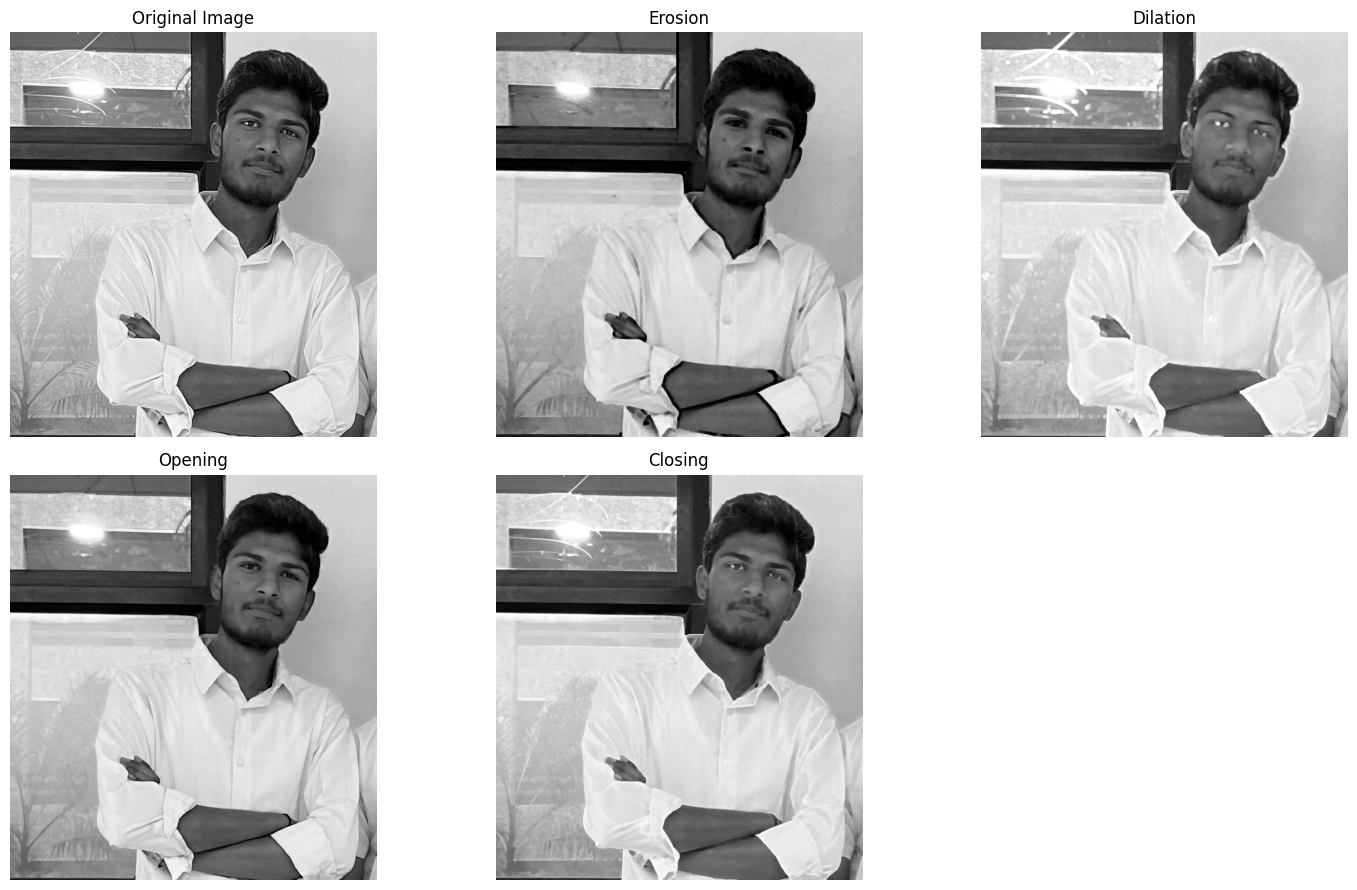

In [6]:
results = [
    ("Original Image", image),
    ("Erosion", erosion),
    ("Dilation", dilation),
    ("Opening", opening),
    ("Closing", closing),
]

plt.figure(figsize=(15, 9))

for index, (title, result) in enumerate(results, start=1):
    plt.subplot(2, 3, index)
    plt.imshow(result, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()